# Training a BBH detector on the v2 dataset — 2-channel 1D ResNet (PyTorch, GPU)

Trains a binary classifier (`y=1` BBH signal injected in real H1+L1 noise, `y=0` noise) on the files written by the v2 dataset notebook
(`train.h5`, `val.h5`, `test.h5`, `bench.h5`, `far.h5` + their `*_meta.csv`).

**Pipeline**

1. Check the GPU and sanity-check the dataset files
2. Load data (kept **on the GPU as float16** if it fits, otherwise streamed from RAM with a prefetch thread)
3. Model: 1D residual CNN on the `(2, 4096)` whitened strain (≈2–3 M parameters)
4. Training: AdamW + one-cycle LR, mixed precision (bf16 if supported, else fp16), EMA weights, label-preserving GPU augmentation, early stopping, **resumable checkpoints**
5. Evaluation that matches the project goal: ROC on `test`, **efficiency vs. SNR** on `bench` at thresholds fixed by the false-alarm probability measured on `far`, robustness to glitches and to mass
6. Saves logits for every split (`predictions.npz`) so the **matched-filter comparison** can reuse exactly the same examples

> Quick pipeline test: set `data_dir="gw_smoke"` and `epochs=3` in the config cell (the smoke dataset is tiny and made with synthetic noise — its numbers mean nothing).

## 1. Configuration

In [1]:
import os, json, time, math, copy, threading, queue, warnings
import numpy as np, pandas as pd, h5py
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from tqdm.auto import tqdm
import torch, torch.nn as nn, torch.nn.functional as F

CFG = dict(
    # ---- data ----
    data_dir="gw_bbh_dataset_v2",      # folder written by the dataset notebook ("gw_smoke" for a quick test)
    run_dir="runs/resnet1d_gn",        # checkpoints, logs and results go here
    train_subset=None,                 # e.g. 20_000 to debug on a slice; None = all
    gpu_resident=False,               # "auto": keep data on GPU (float16) if it fits | True | False
    # ---- model ----
    width=32,                          # base channel count (32 -> ~2.5M params; keep a multiple of 8 for GroupNorm)
    dropout=0.2,
    norm="group",                      # "group" (recommended: no train/eval mismatch, works with small batches) | "batch"
    # ---- optimisation ----
    epochs=30, batch_size=32,         # lower batch_size (128) if you hit CUDA out-of-memory
    lr=7e-4, weight_decay=1e-2, pct_start=0.15, grad_clip=1.0,
    ema_decay=0.999,                   # evaluate/save the EMA weights (set 0 to disable)
    patience=8,                        # early-stopping patience in epochs (monitors val AUC)
    # ---- augmentation (all label-preserving; applied on the GPU) ----
    aug_swap_detectors=True,           # swap H1 <-> L1 (sky prior is symmetric)
    aug_sign_flip=True,                # multiply both channels by -1 (psi -> psi + pi/2)
    aug_max_shift=150,                 # joint circular time shift, +-150 samples (~73 ms); 0 = off
    # ---- misc ----
    seed=1234, resume=True, compile=False,
)
os.makedirs(CFG["run_dir"], exist_ok=True)
print(json.dumps(CFG, indent=1))

/home/willowed/miniconda3/envs/gwml/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{
 "data_dir": "gw_bbh_dataset_v2",
 "run_dir": "runs/resnet1d_gn",
 "train_subset": null,
 "gpu_resident": false,
 "width": 32,
 "dropout": 0.2,
 "norm": "group",
 "epochs": 30,
 "batch_size": 32,
 "lr": 0.0007,
 "weight_decay": 0.01,
 "pct_start": 0.15,
 "grad_clip": 1.0,
 "ema_decay": 0.999,
 "patience": 8,
 "aug_swap_detectors": true,
 "aug_sign_flip": true,
 "aug_max_shift": 150,
 "seed": 1234,
 "resume": true,
 "compile": false
}


## 2. GPU setup

In [2]:
np.random.seed(CFG["seed"]); torch.manual_seed(CFG["seed"])
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    torch.cuda.manual_seed_all(CFG["seed"])
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} | {p.total_memory/2**30:.1f} GiB | compute capability {p.major}.{p.minor} | torch {torch.__version__} | CUDA {torch.version.cuda}")
    AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    USE_AMP = True
else:
    DEVICE = torch.device("cpu"); AMP_DTYPE = torch.float32; USE_AMP = False
    warnings.warn("CUDA is NOT available - running on CPU. Install a CUDA build of PyTorch (https://pytorch.org/get-started/locally/) "
                  "and make sure this notebook uses the same conda env.")
USE_SCALER = USE_AMP and AMP_DTYPE == torch.float16     # loss scaling is only needed for fp16, not bf16
print("device:", DEVICE, "| AMP dtype:", AMP_DTYPE if USE_AMP else "off (fp32)")

def autocast():
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP)

GPU: NVIDIA GeForce RTX 3050 Laptop GPU | 3.7 GiB | compute capability 8.6 | torch 2.14.1+cu130 | CUDA 13.0
device: cuda | AMP dtype: torch.bfloat16


## 3. Dataset sanity check

Confirms every split exists, labels are balanced, there are no NaNs, and that the **tail of each file was actually written**
(an interrupted build leaves an all-zero tail, which would silently poison training).

In [3]:
D = CFG["data_dir"]
def split_path(name, ext="h5"): return os.path.join(D, f"{name}.{ext}" if ext == "h5" else f"{name}_meta.csv")

report = []
for name in ["train", "val", "test", "bench", "far"]:
    ph, pm = split_path(name), split_path(name, "csv")
    if not (os.path.exists(ph) and os.path.exists(pm)):
        raise FileNotFoundError(f"{name}: missing {ph} or {pm}. The dataset build did not finish - re-run build_all() "
                                f"(downloaded noise epochs are cached, so it resumes).")
    with h5py.File(ph, "r") as f:
        N = len(f["y"]); y = f["y"][:]
        k = min(1000, N)
        head, tail = f["X"][:k].astype(np.float32), f["X"][N - k:].astype(np.float32)
        has_S = "S" in f
    bad = []
    if not (np.isfinite(head).all() and np.isfinite(tail).all()): bad.append("non-finite values")
    if tail.std() < 0.1: bad.append("tail looks UNWRITTEN (std~0)")
    report.append(dict(split=name, N=N, shape=f"{(N,)+head.shape[1:]}", frac_signal=float(y.mean()),
                       std_head=float(head.std()), std_tail=float(tail.std()), has_S=has_S, problems="; ".join(bad) or "ok"))
report = pd.DataFrame(report); display(report)
assert (report.problems == "ok").all(), "Dataset problem detected - see table above"
card = json.load(open(os.path.join(D, "dataset_card.json"))) if os.path.exists(os.path.join(D, "dataset_card.json")) else {}
print("preset:", card.get("cfg", {}).get("preset"), "| synthetic_noise:", card.get("cfg", {}).get("synthetic_noise"), "| approximant:", card.get("approximant"))

,split,N,shape,frac_signal,std_head,std_tail,has_S,problems
0,train,100000,"(100000, 2, 4096)",0.5,1.423079,1.197166,False,ok
1,val,10000,"(10000, 2, 4096)",0.5,1.311891,1.058633,True,ok
2,test,10000,"(10000, 2, 4096)",0.5,3.406728,1.120988,True,ok
3,bench,9000,"(9000, 2, 4096)",1.0,2.138209,1.257792,True,ok
4,far,50000,"(50000, 2, 4096)",0.0,1.029191,3.471807,False,ok


preset: medium | synthetic_noise: False | approximant: IMRPhenomPv2


## 4. Data loading

* **GPU-resident** (preferred): the whole split is stored on the GPU as float16 (100 k examples ≈ 1.6 GB) and batches are gathered there — no CPU data loading at all, so the GPU never waits.
  float16 rounding (~1e-3 relative) is negligible next to unit-variance noise.
* **Fallback**: float32 in RAM, with a background thread preparing pinned batches.

In [4]:
class GPULoader:
    def __init__(self, X, y, bs, shuffle, drop_last):
        self.X, self.y, self.bs, self.shuffle, self.drop_last = X, y, bs, shuffle, drop_last
        self.y_np = y.detach().cpu().numpy()
    def __len__(self): return len(self.X) // self.bs if self.drop_last else math.ceil(len(self.X) / self.bs)
    def __iter__(self):
        N = len(self.X)
        perm = torch.randperm(N, device=self.X.device) if self.shuffle else torch.arange(N, device=self.X.device)
        for i in range(0, N, self.bs):
            idx = perm[i:i + self.bs]
            if self.drop_last and len(idx) < self.bs: break
            yield self.X[idx].float(), self.y[idx]

class CPULoader:
    def __init__(self, X, y, bs, shuffle, drop_last, depth=4):
        self.X, self.y_np, self.bs, self.shuffle, self.drop_last, self.depth = X, y, bs, shuffle, drop_last, depth
        self.pin = DEVICE.type == "cuda"
    def __len__(self): return len(self.X) // self.bs if self.drop_last else math.ceil(len(self.X) / self.bs)
    def __iter__(self):
        N = len(self.X)
        order = np.random.permutation(N) if self.shuffle else np.arange(N)
        batches = [order[i:i + self.bs] for i in range(0, N, self.bs)]
        if self.drop_last and len(batches[-1]) < self.bs: batches = batches[:-1]
        q = queue.Queue(maxsize=self.depth)
        def work():
            try:
                for b in batches:
                    b = np.sort(b) if self.shuffle else b
                    xb, yb = torch.from_numpy(self.X[b]), torch.from_numpy(self.y_np[b])
                    if self.pin: xb = xb.pin_memory()
                    q.put((xb, yb))
                q.put(None)
            except Exception as e:
                q.put(e)
        threading.Thread(target=work, daemon=True).start()
        while True:
            item = q.get()
            if item is None: return
            if isinstance(item, Exception): raise item
            yield item[0].to(DEVICE, non_blocking=True), item[1].to(DEVICE, non_blocking=True)

def make_loader(name, bs, shuffle, drop_last, n=None, chunk=8192):
    with h5py.File(split_path(name), "r") as f:
        N = len(f["y"]) if n is None else min(n, len(f["y"]))
        y = f["y"][:N].astype(np.float32); shape = f["X"].shape[1:]
    need = N * int(np.prod(shape)) * 2
    use_gpu = False
    if DEVICE.type == "cuda" and CFG["gpu_resident"] is not False:
        free = torch.cuda.mem_get_info()[0]
        use_gpu = CFG["gpu_resident"] is True or need < 0.30 * free
    print(f"[{name}] N={N}  {'GPU-resident fp16' if use_gpu else 'CPU float32 + prefetch'}  ({need/2**30:.2f} GiB as fp16)")
    with h5py.File(split_path(name), "r") as f:
        d = f["X"]
        if use_gpu:
            Xg = torch.empty((N,) + shape, dtype=torch.float16, device=DEVICE)
            for a in tqdm(range(0, N, chunk), desc=f"load {name}", leave=False):
                Xg[a:a + chunk] = torch.from_numpy(d[a:min(N, a + chunk)].astype(np.float16)).to(DEVICE)
            return GPULoader(Xg, torch.from_numpy(y).to(DEVICE), bs, shuffle, drop_last)
        X = np.empty((N,) + shape, dtype=np.float32)
        for a in tqdm(range(0, N, chunk), desc=f"load {name}", leave=False):
            X[a:a + chunk] = d[a:min(N, a + chunk)]
        return CPULoader(X, y, bs, shuffle, drop_last)

train_loader = make_loader("train", CFG["batch_size"], shuffle=True,  drop_last=True,  n=CFG["train_subset"])
val_loader   = make_loader("val",   1024,              shuffle=False, drop_last=False)
print("train batches/epoch:", len(train_loader), "| val batches:", len(val_loader))

[train] N=100000  CPU float32 + prefetch  (1.53 GiB as fp16)


[val] N=10000  CPU float32 + prefetch  (0.15 GiB as fp16)


train batches/epoch: 3125 | val batches: 10


## 5. Model

A residual 1D CNN (GroupNorm by default — BatchNorm's running statistics disagreed with its batch statistics during training, which wrecked evaluation): 31-tap stem → six stages of two residual blocks (the last five halve the length: 4096 → 128) → global average **and** max pooling (max pooling keeps short glitches/mergers visible) → small MLP → one logit.
H1 and L1 enter as two channels of the first convolution, so the network can learn the inter-detector time delay and amplitude consistency directly.

In [5]:
def make_norm(kind, c):
    return nn.GroupNorm(8, c) if kind == "group" else nn.BatchNorm1d(c)

class ResBlock(nn.Module):
    def __init__(self, cin, cout, stride=1, k=7, norm="group"):
        super().__init__()
        self.c1 = nn.Conv1d(cin, cout, k, stride, k // 2, bias=False); self.b1 = make_norm(norm, cout)
        self.c2 = nn.Conv1d(cout, cout, k, 1, k // 2, bias=False);     self.b2 = make_norm(norm, cout)
        self.short = None if (cin == cout and stride == 1) else nn.Sequential(
            nn.Conv1d(cin, cout, 1, stride, bias=False), make_norm(norm, cout))
        self.act = nn.SiLU()
    def forward(self, x):
        y = self.act(self.b1(self.c1(x)))
        y = self.b2(self.c2(y))
        return self.act(y + (x if self.short is None else self.short(x)))

class GWNet(nn.Module):
    def __init__(self, width=32, dropout=0.2, in_ch=2, norm="group"):
        super().__init__()
        w = width
        self.stem = nn.Sequential(nn.Conv1d(in_ch, w, 31, 1, 15, bias=False), make_norm(norm, w), nn.SiLU())
        plan = [(w, 1), (2 * w, 2), (4 * w, 2), (8 * w, 2), (8 * w, 2), (8 * w, 2)]
        layers, cin = [], w
        for cout, stride in plan:
            layers += [ResBlock(cin, cout, stride, norm=norm), ResBlock(cout, cout, 1, norm=norm)]
            cin = cout
        self.body = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.Linear(2 * cin, 256), nn.SiLU(), nn.Dropout(dropout), nn.Linear(256, 1))
    def forward(self, x):
        h = self.body(self.stem(x))
        h = torch.cat([h.mean(-1), h.amax(-1)], dim=1)
        return self.head(h).squeeze(-1)           # raw logit

def build_model():
    m = GWNet(CFG["width"], CFG["dropout"], norm=CFG["norm"]).to(DEVICE)
    return m

model = build_model()
print(f"parameters: {sum(p.numel() for p in model.parameters())/1e6:.2f} M")
with torch.no_grad():
    print("output shape check:", model.eval()(torch.zeros(4, 2, 4096, device=DEVICE)).shape)

parameters: 6.12 M
output shape check: torch.Size([4])


## 6. Metrics, augmentation, EMA
`TPR @ FPR=1 %` on the validation noise is logged next to AUC, because the project cares about the low-false-alarm regime rather than average ranking.

In [6]:
def auc_score(y, s):
    y = np.asarray(y).astype(bool); r = rankdata(s)
    n1, n0 = y.sum(), (~y).sum()
    return float((r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

def threshold_at_fap(noise_scores, fap):
    """Score threshold such that a fraction `fap` of the noise-only examples lies above it."""
    s = np.sort(np.asarray(noise_scores))[::-1]
    return float(s[min(int(fap * len(s)), len(s) - 1)])

def tpr_at_fpr(y, s, fpr):
    y = np.asarray(y).astype(bool)
    return float((s[y] > threshold_at_fap(s[~y], fpr)).mean())

@torch.no_grad()
def predict_loader(m, loader):
    m.eval(); out = []
    for xb, _ in loader:
        with autocast(): out.append(m(xb).float().cpu())
    return torch.cat(out).numpy()

def evaluate(m, loader):
    lo = predict_loader(m, loader); y = loader.y_np
    loss = float(F.binary_cross_entropy_with_logits(torch.from_numpy(lo), torch.from_numpy(y)))
    return dict(loss=loss, acc=float(((lo > 0) == (y > 0.5)).mean()), auc=auc_score(y, lo), tpr1=tpr_at_fpr(y, lo, 0.01))

def augment(x):
    """x: (B,2,N) float32 on the device. All transforms keep the label valid."""
    B, C, N = x.shape
    if CFG["aug_swap_detectors"]:
        sw = torch.rand(B, device=x.device) < 0.5
        x = torch.where(sw[:, None, None], x.flip(1), x)
    if CFG["aug_sign_flip"]:
        sg = (torch.rand(B, device=x.device) < 0.5).float() * 2 - 1
        x = x * sg[:, None, None]
    S = CFG["aug_max_shift"]
    if S > 0:
        sh = torch.randint(-S, S + 1, (B,), device=x.device)
        idx = (torch.arange(N, device=x.device)[None, :] - sh[:, None]) % N
        x = x.gather(2, idx[:, None, :].expand(B, C, N))
    return x

class EMA:
    def __init__(self, m, decay):
        self.decay = decay; self.m = copy.deepcopy(m).eval()
        for p in self.m.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(self, m):
        for pe, p in zip(self.m.parameters(), m.parameters()): pe.mul_(self.decay).add_(p.detach(), alpha=1 - self.decay)
        for be, b in zip(self.m.buffers(), m.buffers()):      # BatchNorm statistics (none with GroupNorm)
            if be.dtype.is_floating_point: be.mul_(self.decay).add_(b, alpha=1 - self.decay)
            else: be.copy_(b)

## 7. Training
Checkpoints: `last.pt` is written every epoch (training resumes from it automatically if you re-run this cell after an interruption — delete the run folder or set `resume=False` if you change hyper-parameters),
`best.pt` holds the best EMA weights by validation AUC.

In [7]:
run = CFG["run_dir"]; P_LAST, P_BEST, P_HIST = [os.path.join(run, f) for f in ("last.pt", "best.pt", "history.json")]

model = build_model()
net = torch.compile(model) if CFG["compile"] else model
ema = EMA(model, CFG["ema_decay"]) if CFG["ema_decay"] > 0 else None
decay_p = [p for n, p in model.named_parameters() if p.ndim > 1]
nodecay_p = [p for n, p in model.named_parameters() if p.ndim <= 1]
opt = torch.optim.AdamW([dict(params=decay_p, weight_decay=CFG["weight_decay"]), dict(params=nodecay_p, weight_decay=0.0)],
                        lr=CFG["lr"], betas=(0.9, 0.99))
steps_per_epoch = len(train_loader); total_steps = CFG["epochs"] * steps_per_epoch
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["lr"], total_steps=total_steps, pct_start=CFG["pct_start"],
                                            div_factor=20, final_div_factor=200)
try:    scaler = torch.amp.GradScaler("cuda", enabled=USE_SCALER)
except Exception: scaler = torch.cuda.amp.GradScaler(enabled=USE_SCALER)

history, best_auc, best_ep, start_ep = [], -1.0, -1, 0
if CFG["resume"] and os.path.exists(P_LAST):
    ck = torch.load(P_LAST, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
    if ema is not None and ck.get("ema"): ema.m.load_state_dict(ck["ema"])
    if USE_SCALER and ck.get("scaler"): scaler.load_state_dict(ck["scaler"])
    history, best_auc, best_ep, start_ep = ck["history"], ck["best_auc"], ck["best_ep"], ck["epoch"] + 1
    print(f"resumed from epoch {start_ep} (best val AUC so far {best_auc:.4f} @ epoch {best_ep})")

def run_training():
    global best_auc, best_ep
    eval_model = ema.m if ema is not None else model
    for ep in range(start_ep, CFG["epochs"]):
        t0 = time.time(); model.train()
        tl = torch.zeros((), device=DEVICE); tc = torch.zeros((), device=DEVICE); seen = 0
        for xb, yb in tqdm(train_loader, desc=f"epoch {ep+1}/{CFG['epochs']}", leave=False):
            xb = augment(xb)
            with autocast(): logit = net(xb)
            loss = F.binary_cross_entropy_with_logits(logit.float(), yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
            scaler.step(opt); scaler.update(); sched.step()
            if ema is not None: ema.update(model)
            tl += loss.detach() * len(yb); tc += ((logit.detach() > 0) == (yb > 0.5)).sum(); seen += len(yb)
        v = evaluate(eval_model, val_loader)
        rec = dict(epoch=ep, train_loss=float(tl) / seen, train_acc=float(tc) / seen, val_loss=v["loss"], val_acc=v["acc"],
                   val_auc=v["auc"], val_tpr1=v["tpr1"], lr=sched.get_last_lr()[0], sec=time.time() - t0)
        history.append(rec)
        improved = v["auc"] > best_auc
        if improved:
            best_auc, best_ep = v["auc"], ep
            torch.save(dict(model=eval_model.state_dict(), cfg=CFG, epoch=ep, val=v), P_BEST)
        torch.save(dict(model=model.state_dict(), ema=ema.m.state_dict() if ema is not None else None, opt=opt.state_dict(),
                        sched=sched.state_dict(), scaler=scaler.state_dict() if USE_SCALER else None, history=history,
                        best_auc=best_auc, best_ep=best_ep, epoch=ep, cfg=CFG), P_LAST)
        json.dump(history, open(P_HIST, "w"), indent=1)
        print(f"ep {ep+1:3d}/{CFG['epochs']} | train loss {rec['train_loss']:.4f} acc {rec['train_acc']:.3f} | "
              f"val loss {v['loss']:.4f} acc {v['acc']:.3f} AUC {v['auc']:.4f} TPR@1%FPR {v['tpr1']:.3f} | "
              f"lr {rec['lr']:.2e} | {rec['sec']:.0f}s {'  * best' if improved else ''}")
        if ep - best_ep >= CFG["patience"]:
            print(f"early stopping: no val-AUC improvement for {CFG['patience']} epochs"); break

run_training()

[W1008 21:02:18.963508233 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 536870912 bytes (free: 480247808, total: 3951296512).
[W1008 21:02:20.134355818 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 538968064 bytes (free: 213909504, total: 3951296512).
[W1008 21:02:25.490931326 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 536870912 bytes (free: 274726912, total: 3951296512).
[W1008 21:02:25.678045605 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 538968064 bytes (free: 111149056, total: 3951296512).


ep   1/30 | train loss 0.5151 acc 0.731 | val loss 0.4573 acc 0.773 AUC 0.8250 TPR@1%FPR 0.521 | lr 1.13e-04 | 363s   * best


[W1008 21:08:22.545420109 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 536870912 bytes (free: 249561088, total: 3951296512).
[W1008 21:08:22.738344098 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 538968064 bytes (free: 146800640, total: 3951296512).


ep   2/30 | train loss 0.4681 acc 0.768 | val loss 0.4302 acc 0.794 AUC 0.8380 TPR@1%FPR 0.573 | lr 3.10e-04 | 353s   * best


ep   3/30 | train loss 0.4547 acc 0.777 | val loss 0.4231 acc 0.799 AUC 0.8417 TPR@1%FPR 0.588 | lr 5.34e-04 | 354s   * best


...

ep  24/30 | train loss 0.3486 acc 0.842 | val loss 0.4124 acc 0.810 AUC 0.8633 TPR@1%FPR 0.628 | lr 9.15e-05 | 352s 


ep  25/30 | train loss 0.3441 acc 0.845 | val loss 0.4168 acc 0.809 AUC 0.8619 TPR@1%FPR 0.627 | lr 6.45e-05 | 352s 


ep  26/30 | train loss 0.3384 acc 0.848 | val loss 0.4220 acc 0.809 AUC 0.8609 TPR@1%FPR 0.627 | lr 4.18e-05 | 352s 


ep  27/30 | train loss 0.3337 acc 0.851 | val loss 0.4267 acc 0.809 AUC 0.8602 TPR@1%FPR 0.626 | lr 2.38e-05 | 352s 


ep  28/30 | train loss 0.3309 acc 0.852 | val loss 0.4306 acc 0.807 AUC 0.8596 TPR@1%FPR 0.624 | lr 1.07e-05 | 352s 
early stopping: no val-AUC improvement for 8 epochs


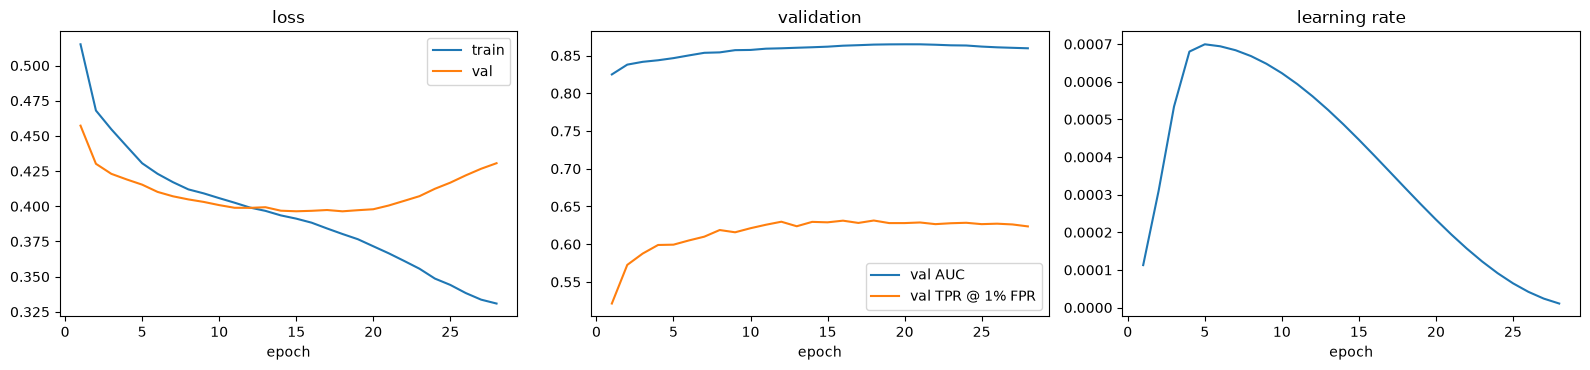

best epoch: 20  val AUC 0.8649


In [8]:
H = pd.DataFrame(json.load(open(P_HIST)))
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(H.epoch + 1, H.train_loss, label="train"); ax[0].plot(H.epoch + 1, H.val_loss, label="val"); ax[0].set(title="loss", xlabel="epoch"); ax[0].legend()
ax[1].plot(H.epoch + 1, H.val_auc, label="val AUC"); ax[1].plot(H.epoch + 1, H.val_tpr1, label="val TPR @ 1% FPR"); ax[1].set(title="validation", xlabel="epoch"); ax[1].legend()
ax[2].plot(H.epoch + 1, H.lr); ax[2].set(title="learning rate", xlabel="epoch")
plt.tight_layout(); plt.savefig(os.path.join(run, "training_curves.png"), dpi=130); plt.show()
print(f"best epoch: {int(H.val_auc.idxmax()) + 1}  val AUC {H.val_auc.max():.4f}")

## 8. Evaluation on held-out data
`val`, `test`, `bench` and `far` are built from **noise epochs the network never saw** (the dataset is split by time, not by example).
All five questions below use the best EMA checkpoint.

In [15]:
ck = torch.load(P_BEST, map_location=DEVICE, weights_only=False)
best_model = build_model(); best_model.load_state_dict(ck["model"]); best_model.eval()
print(f"loaded best checkpoint: epoch {ck['epoch']+1}, val AUC {ck['val']['auc']:.4f}")

@torch.no_grad()
def predict_h5(m, path, bs=1024):
    """Stream a split from disk in float32 (no precision loss from the float16 storage used for training)."""
    m.eval(); out = []
    with h5py.File(path, "r") as f:
        X, y = f["X"], f["y"][:]
        for a in tqdm(range(0, len(y), bs), desc=os.path.basename(path), leave=False):
            xb = torch.from_numpy(X[a:a + bs].astype(np.float32)).to(DEVICE)
            with autocast(): out.append(m(xb).float().cpu().numpy())
    return np.concatenate(out), y

PRED, META = {}, {}
for name in ["val", "test", "bench", "far"]:
    PRED[name], y_ = predict_h5(best_model, split_path(name)); META[name] = pd.read_csv(split_path(name, "csv")); META[name]["label"] = y_
    assert len(PRED[name]) == len(META[name])
np.savez_compressed(os.path.join(run, "predictions.npz"), **{f"{k}_logit": v for k, v in PRED.items()},
                    **{f"{k}_label": META[k].label.values for k in PRED})
print({k: v.shape for k, v in PRED.items()})

loaded best checkpoint: epoch 20, val AUC 0.8649


val.h5:   0%|          | 0/10 [00:00<?, ?it/s][W1009 07:15:28.902516184 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 538968064 bytes (free: 88080384, total: 3951296512).
[W1009 07:15:29.061401347 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 538968064 bytes (free: 320864256, total: 3951296512).
[W1009 07:15:29.114969120 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 536870912 bytes (free: 318767104, total: 3951296512).
[W1009 07:15:29.145258230 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 536870912 bytes (free: 226492416, total: 3951296512).
                                                        

{'val': (10000,), 'test': (10000,), 'bench': (9000,), 'far': (50000,)}


### 8.1 ROC on the balanced test set

test: N=10000  AUC=0.8649  accuracy@logit0=0.8207
  TPR @ FPR=0.01: 0.6422   (noise windows in test: 5000)
  TPR @ FPR=0.001: 0.6000   (noise windows in test: 5000)


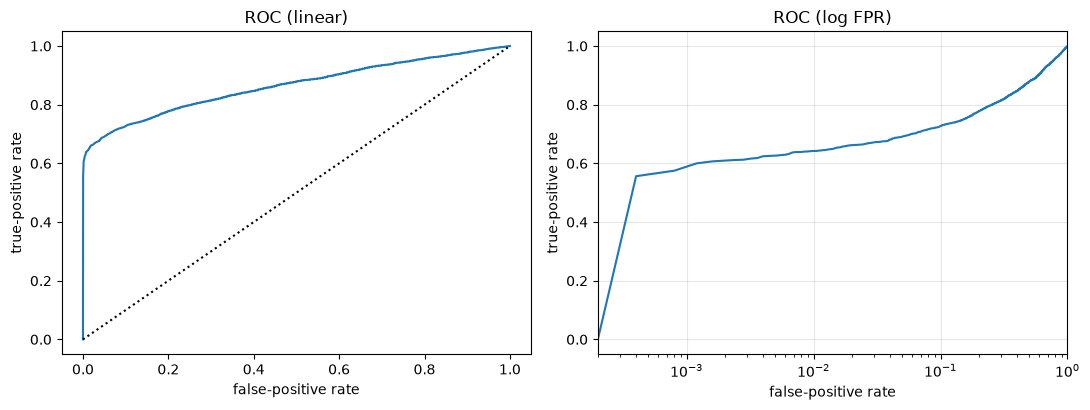

In [16]:
yt, st = META["test"].label.values, PRED["test"]
print(f"test: N={len(yt)}  AUC={auc_score(yt, st):.4f}  accuracy@logit0={((st > 0) == (yt == 1)).mean():.4f}")
for f_ in (1e-2, 1e-3):
    print(f"  TPR @ FPR={f_:g}: {tpr_at_fpr(yt, st, f_):.4f}   (noise windows in test: {(yt == 0).sum()})")

neg = np.sort(st[yt == 0])[::-1]; pos = st[yt == 1]
thr = np.concatenate([[np.inf], neg]); fpr = np.arange(len(thr)) / len(neg)
tpr = np.array([(pos > t).mean() for t in thr[:: max(1, len(thr) // 2000)]]); fpr = fpr[:: max(1, len(thr) // 2000)]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set(xlabel="false-positive rate", ylabel="true-positive rate", title="ROC (linear)")
ax[1].semilogx(np.maximum(fpr, 1 / len(neg)), tpr); ax[1].set(xlabel="false-positive rate", ylabel="true-positive rate", title="ROC (log FPR)", xlim=(1 / len(neg), 1)); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(run, "roc_test.png"), dpi=130); plt.show()

### 8.2 Efficiency vs. network SNR (the central comparison with matched filtering)

Thresholds are set from the **noise-only `far` split**: a threshold at false-alarm probability `p` is the score exceeded by a fraction `p` of `far` windows.
Detection efficiency is then the fraction of `bench` signals above that threshold at each fixed optimal network SNR.
(Each window is 2 s long, so `p` is a *per-window* probability; windows overlapping in time are not independent, so convert to a physical false-alarm *rate* only after the time-slide analysis.)

far windows: 50000 | thresholds (logit): {0.01: 1.461, 0.001: 4.594}


,snr,n,eff@0.01,eff@0.001
0,4.0,1000,0.024,0.005
1,5.0,1000,0.074,0.020
2,6.0,1000,0.158,0.080
3,8.0,1000,0.519,0.371
4,10.0,1000,0.865,0.730
5,12.0,1000,0.976,0.925
6,15.0,1000,0.991,0.986
7,20.0,1000,1.000,0.997
8,30.0,1000,0.999,0.999


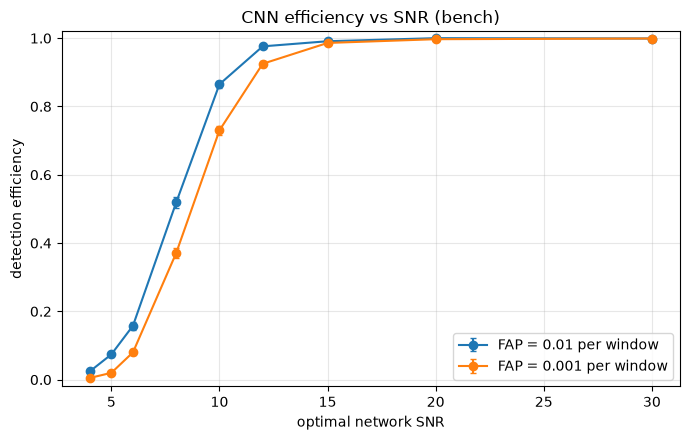

In [17]:
far, bm = PRED["far"], META["bench"].copy(); bm["score"] = PRED["bench"]
FAPS = [f for f in (1e-2, 1e-3, 1e-4) if f * len(far) >= 10]
THR = {f: threshold_at_fap(far, f) for f in FAPS}
print("far windows:", len(far), "| thresholds (logit):", {f: round(t, 3) for f, t in THR.items()})

bm["snr_bin"] = bm.snr_net.round(3)
rows = []
for s, g in bm.groupby("snr_bin"):
    r = dict(snr=s, n=len(g))
    for f in FAPS: r[f"eff@{f:g}"] = (g.score > THR[f]).mean()
    rows.append(r)
EFF = pd.DataFrame(rows); display(EFF.round(3))

fig, ax = plt.subplots(figsize=(7, 4.5))
for f in FAPS:
    p, n = EFF[f"eff@{f:g}"].values, EFF.n.values
    ax.errorbar(EFF.snr, p, yerr=np.sqrt(p * (1 - p) / n), marker="o", capsize=2, label=f"FAP = {f:g} per window")
ax.set(xlabel="optimal network SNR", ylabel="detection efficiency", title="CNN efficiency vs SNR (bench)", ylim=(-0.02, 1.02)); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(run, "efficiency_vs_snr.png"), dpi=130); plt.show()
EFF.to_csv(os.path.join(run, "efficiency_vs_snr.csv"), index=False)

### 8.3 Robustness to glitches
Glitches appear at the same rate in both classes, so a good model must not use them as a shortcut. Here: how many glitchy vs. clean **noise** windows exceed each threshold, and efficiency on glitchy vs. clean **signals**.

In [18]:
fm = META["far"]; gl_far = fm.glitch_type.notna().values
bm["glitch"] = bm.glitch_type.notna()
rows = []
for f in FAPS:
    t = THR[f]; above = far > t
    rows.append(dict(FAP=f, noise_clean_FAP=above[~gl_far].mean(), noise_glitchy_FAP=above[gl_far].mean() if gl_far.any() else np.nan,
                     n_glitchy_noise=int(gl_far.sum()),
                     **{f"glitch:{k}": above[(fm.glitch_type == k).values].mean() for k in sorted(fm.glitch_type.dropna().unique())}))
display(pd.DataFrame(rows).round(5))

sel = bm[(bm.snr_bin >= 8) & (bm.snr_bin <= 15)]
display(sel.groupby("glitch").apply(lambda g: pd.Series({f"eff@{f:g}": (g.score > THR[f]).mean() for f in FAPS} | {"n": len(g)}), include_groups=False).round(3)
        .rename(index={False: "signal, no glitch", True: "signal + glitch"}))

,FAP,noise_clean_FAP,noise_glitchy_FAP,n_glitchy_noise,glitch:blip,glitch:chirping_whistle,glitch:scattered_light,glitch:sine_gaussian
0,0.010,0.00731,0.01610,14972,0.01072,0.02479,0.01567,0.01327
1,0.001,0.00029,0.00267,14972,0.00107,0.00350,0.00372,0.00239


,eff@0.01,eff@0.001,n
glitch,,,
"signal, no glitch",0.846,0.773,2820.0
signal + glitch,0.817,0.704,1180.0


### 8.4 Efficiency vs. total mass (bench signals with SNR 8–15, FAP = 1e-3 or the strictest available)

,n,eff
mbin,,
"(10, 25]",1986.0,0.649
"(25, 40]",432.0,0.745
"(40, 60]",367.0,0.774
"(60, 80]",351.0,0.880
"(80, 110]",397.0,0.919
"(110, 150]",337.0,0.944
"(150, 210]",130.0,0.969


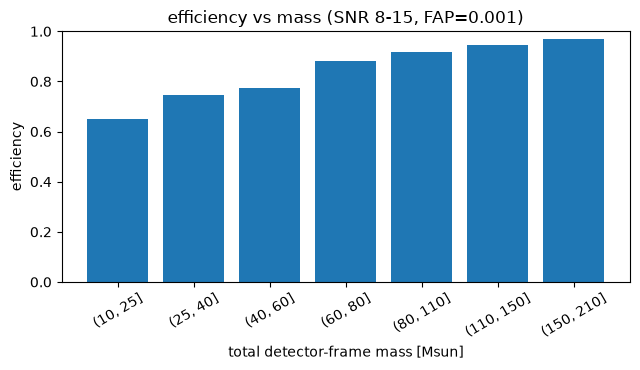

In [19]:
f_ref = 1e-3 if 1e-3 in THR else FAPS[-1]
sel = bm[(bm.snr_bin >= 8) & (bm.snr_bin <= 15)].copy()
edges = [10, 25, 40, 60, 80, 110, 150, 210]
sel["mbin"] = pd.cut(sel.mtotal, edges)
tab = sel.groupby("mbin", observed=True).apply(lambda g: pd.Series(dict(n=len(g), eff=(g.score > THR[f_ref]).mean())), include_groups=False)
display(tab.round(3))
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar([str(i) for i in tab.index], tab.eff, color="C0"); ax.set(xlabel="total detector-frame mass [Msun]", ylabel="efficiency", title=f"efficiency vs mass (SNR 8-15, FAP={f_ref:g})", ylim=(0, 1))
plt.xticks(rotation=30); plt.tight_layout(); plt.savefig(os.path.join(run, "efficiency_vs_mass.png"), dpi=130); plt.show()

### 8.5 Save a results summary

In [21]:
f_ref = 1e-3
sel = bm[(bm.snr_bin >= 8) & (bm.snr_bin <= 15)].copy()
sel["mbin"] = pd.cut(sel.mtotal, [10, 25, 40, 60, 80, 110, 150, 210])
tab = sel.groupby(["snr_bin", "mbin"], observed=True).apply(lambda g: (g.score > THR[f_ref]).mean(), include_groups=False).unstack("snr_bin")
display(tab.round(3))

snr_bin,8.0,10.0,12.0,15.0
mbin,,,,
"(10, 25]",0.155,0.548,0.876,0.980
"(25, 40]",0.266,0.752,0.990,0.983
"(40, 60]",0.374,0.822,0.937,0.986
"(60, 80]",0.614,0.918,1.000,1.000
"(80, 110]",0.720,0.974,0.977,0.990
"(110, 150]",0.824,1.000,0.985,1.000
"(150, 210]",0.875,1.000,1.000,1.000


In [20]:
summary = dict(
    best_epoch=int(ck["epoch"]) + 1, val_auc=ck["val"]["auc"],
    test_auc=auc_score(yt, st), test_tpr_at_fpr={str(f): tpr_at_fpr(yt, st, f) for f in (1e-2, 1e-3)},
    far_thresholds_logit={str(f): t for f, t in THR.items()}, n_far=int(len(far)),
    efficiency_vs_snr=EFF.round(4).to_dict(orient="list"),
    config=CFG, params_M=sum(p.numel() for p in best_model.parameters()) / 1e6,
)
json.dump(summary, open(os.path.join(run, "eval_results.json"), "w"), indent=1, default=float)
print("saved to", run, "->", sorted(os.listdir(run)))

saved to runs/resnet1d_gn -> ['best.pt', 'efficiency_vs_mass.png', 'efficiency_vs_snr.csv', 'efficiency_vs_snr.png', 'eval_results.json', 'history.json', 'last.pt', 'predictions.npz', 'roc_test.png', 'training_curves.png']


## 9. Next steps

1. **Matched-filter baseline** on the *same* `bench`/`far` examples: whiten a template bank with the PSDs in `psd_table.h5` (indexed by `epoch_*`/`blk_*` in the metadata) and compare efficiency-vs-SNR at equal false-alarm probability. `predictions.npz` stores the CNN logits for those exact rows.
2. **Ablations** worth reporting: Gaussian (`synthetic_noise=True`) vs. real noise, with/without glitches, 1 vs. 2 detectors, and 3+ random seeds (report mean ± std — a single run cannot support claims about small differences).
3. **Scaling**: rebuild with the `large` preset and set `gpu_resident=False` if it no longer fits in VRAM; try `width=48/64`, longer training, or test-time averaging over the augmentations (swap/sign flip).
4. **Calibration to a physical false-alarm rate** by time-sliding real data far beyond the 2 s windows used here.